In [2]:
!pip install opencv-python numpy matplotlib

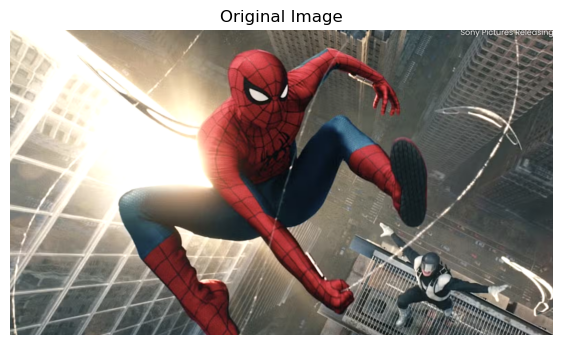

Image dimensions (height, width): 926 1646
Number of channels: 3
Data type: uint8
Pixel at (x=50, y=50) in BGR: [221 241 253]


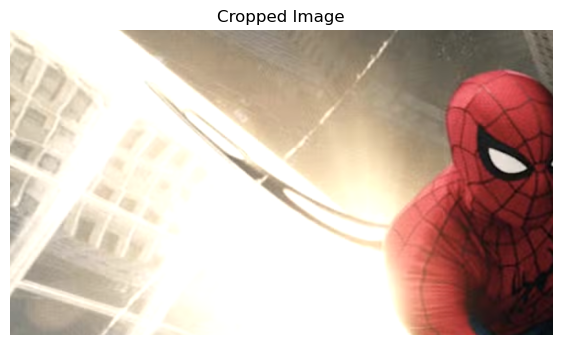

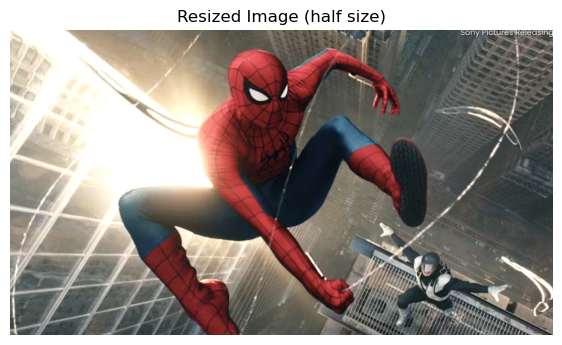

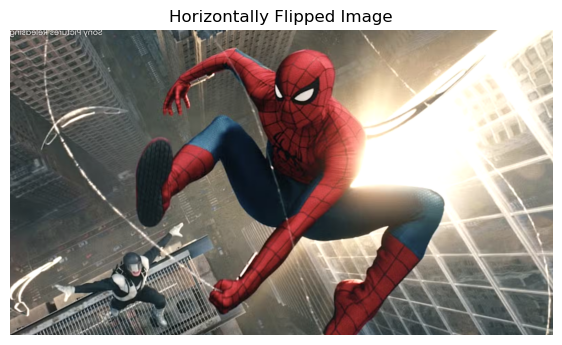

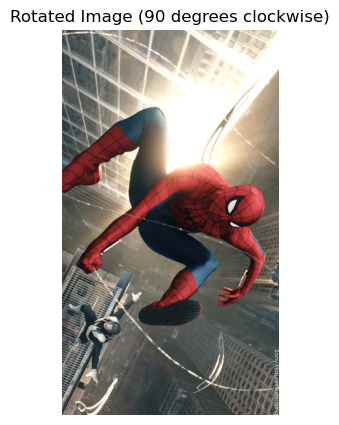

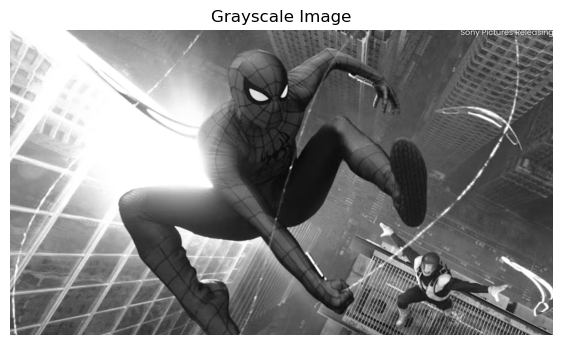

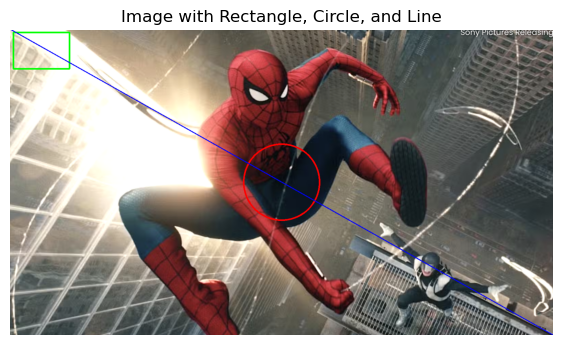

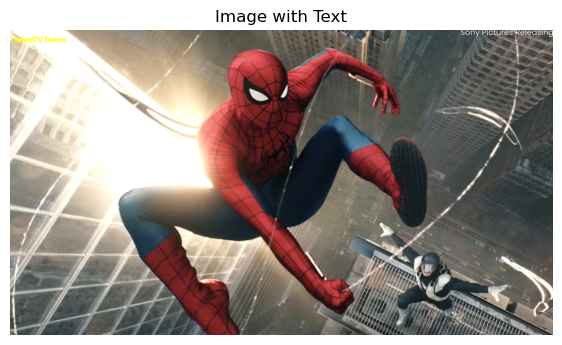

Saved grayscale.jpg, cropped.jpg, and shapes_and_text.jpg


In [6]:
# EXPERIMENT 1: BASIC IMAGE OPERATIONS USING OPENCV
# Operations: read/display, pixel information, crop, resize, flip, rotate,
# grayscale, draw shapes, and write text.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Change this to the path of your own image.
IMAGE_PATH = "input.png"

def show_image(title, image, cmap=None):
    """Display an image using Matplotlib."""
    plt.figure(figsize=(7, 5))
    if len(image.shape) == 3:
        # OpenCV loads color images as BGR; convert to RGB for Matplotlib.
        image_to_show = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.imshow(image_to_show)
    else:
        plt.imshow(image, cmap=cmap or "gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

# (i) Read and display an image
image = cv2.imread(IMAGE_PATH)
if image is None:
    raise FileNotFoundError(
        f"Could not read '{IMAGE_PATH}'. Put an image in this folder "
        "or update IMAGE_PATH to the correct file path."
    )

show_image("Original Image", image)

# (ii) Display image and pixel information
height, width = image.shape[:2]
channels = 1 if len(image.shape) == 2 else image.shape[2]
print("Image dimensions (height, width):", height, width)
print("Number of channels:", channels)
print("Data type:", image.dtype)

# Pixel coordinates: x is column, y is row.
x, y = min(50, width - 1), min(50, height - 1)
print(f"Pixel at (x={x}, y={y}) in BGR:", image[y, x])

# (iii) Crop an image (rows first, then columns)
crop_h = max(1, height // 2)
crop_w = max(1, width // 2)
cropped = image[0:crop_h, 0:crop_w]
show_image("Cropped Image", cropped)

# (iv) Resize an image
resized = cv2.resize(image, (width // 2 or 1, height // 2 or 1))
show_image("Resized Image (half size)", resized)

# (v) Flip an image: 1 = horizontal, 0 = vertical, -1 = both
flipped = cv2.flip(image, 1)
show_image("Horizontally Flipped Image", flipped)

# (vi) Rotate an image by 90 degrees clockwise
rotated = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
show_image("Rotated Image (90 degrees clockwise)", rotated)

# (vii) Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
show_image("Grayscale Image", gray)

# (viii) Draw shapes on a copy of the image
shapes = image.copy()
cv2.rectangle(shapes, (10, 10), (min(width - 1, 180), min(height - 1, 120)),
              (0, 255, 0), 3)
cv2.circle(shapes, (width // 2, height // 2), max(5, min(width, height) // 8),
           (0, 0, 255), 3)
cv2.line(shapes, (0, 0), (width - 1, height - 1), (255, 0, 0), 2)
show_image("Image with Rectangle, Circle, and Line", shapes)

# (ix) Write text on the image
text_image = image.copy()
cv2.putText(text_image, "OpenCV Demo",
            (10, min(height - 10, 40)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
show_image("Image with Text", text_image)

# Optional: save selected outputs
cv2.imwrite("grayscale.jpg", gray)
cv2.imwrite("cropped.jpg", cropped)
cv2.imwrite("shapes_and_text.jpg", text_image)
print("Saved grayscale.jpg, cropped.jpg, and shapes_and_text.jpg")
